# Test accuracy across recording conditions

In [1]:
%matplotlib inline
from pathlib import Path
from datetime import datetime, timedelta, timezone
from importlib.metadata import version
import hashlib
import json
import cloudpickle
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.signal import welch
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.metrics import accuracy_score

mne.set_log_level('WARNING')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
ROOT = Path.cwd()
if not (ROOT / 'environment.yml').is_file():
    ROOT = ROOT.parent
assert (ROOT / 'environment.yml').is_file(), 'Open the project root or training folder.'
SOURCE = ROOT / 'results/hackathon_pipeline'
OUTPUT = ROOT / 'results/condition_comparison'
OUTPUT.mkdir(parents=True, exist_ok=True)
reference = json.loads((SOURCE / 'metrics.json').read_text())
settings = reference['preprocessing']
channels = reference['channels']
BANDS = reference['feature_bands_hz']
DROP_CHANNELS = settings['dropped_channels']
CLOCK_OFFSET_S, SAMPLE_RATE = settings['clock_offset_s'], settings['sample_rate_hz']
BANDPASS, LINE_FREQ = settings['bandpass_hz'], settings['notch_hz'][0]
BAD_Z, FLAT_SD = settings['bad_channel_robust_z'], settings['flat_sd_volts']
ICA_MAX_COMPONENTS, ICA_MAX_EXCLUDE = settings['ica_max_components'], settings['ica_max_exclude']
BASELINE_SECONDS, EPOCH_SECONDS = -settings['baseline_seconds'][0], settings['epoch_seconds']
assert (len(channels), SAMPLE_RATE, CLOCK_OFFSET_S, EPOCH_SECONDS) == (21, 500, 15.6, 1)

In [3]:
spoken_info = pd.read_csv(SOURCE / 'epoch_split.csv')
with np.load(SOURCE / 'epochs.npz', allow_pickle=False) as saved:
    X_spoken, y_spoken = saved['X'], saved['y']
    np.testing.assert_array_equal(saved['trial'], spoken_info['trial'])
    np.testing.assert_array_equal(saved['split'], spoken_info['split'])
    np.testing.assert_array_equal(y_spoken, spoken_info['label'])
    assert saved['channels'].tolist() == channels and float(saved['sfreq']) == SAMPLE_RATE
assert X_spoken.shape == (772, 21, 500) and np.isfinite(X_spoken).all()
spoken_info = spoken_info.drop(columns='split').assign(experiment=2)
saved_test = pd.read_csv(SOURCE / 'test_predictions.csv')
np.testing.assert_array_equal(spoken_info.loc[spoken_info['trial'].eq(5), 'event_id'], saved_test['event_id'])
print(f'Loaded {len(X_spoken)} spoken epochs, including {len(saved_test)} Trial 5 test epochs.')

Loaded 772 spoken epochs, including 234 Trial 5 test epochs.


In [4]:
def load_mental(trial):
    eeg = ROOT / 'data/EEG Data/Experiment 1 - Mental' / f'Trial {trial}' / 'subject1.cnt'
    stimulus = ROOT / 'data/Stimulation Data/Experiment 1' / f'Trial {trial}' / 'subject1_all.csv'
    raw = mne.io.read_raw_ant(eeg, preload=True, verbose='error')
    raw.drop_channels([channel for channel in raw.ch_names if channel.upper() in DROP_CHANNELS])
    original_start, original_count = raw.info['meas_date'], int(raw.n_times)
    first, count = 0, original_count
    segment = eeg.with_suffix('.seg')
    if segment.exists():
        lines = segment.read_text().splitlines()
        assert len(lines) == 2 and int(lines[0].split('=')[1]) == 2
        day, fraction, count = lines[1].split()
        count = int(count)
        first = original_count - count
        assert trial == 2 and (first, count) == (187024, 307392)
        resumed = datetime(1899, 12, 30, tzinfo=timezone.utc) + timedelta(days=float(day), seconds=float(fraction))
        raw = mne.io.RawArray(raw.get_data(start=first), raw.info.copy(), verbose='error')
        raw.set_meas_date(resumed)
    assert (trial == 2) == segment.exists()
    raw.set_montage(settings['montage'], match_case=False, on_missing='raise')
    log = pd.read_csv(stimulus, keep_default_na=False)
    assert log['seq'].is_unique and (log['offset_epoch_ms'] > log['onset_epoch_ms']).all()
    assert (log['onset_epoch_ms'].to_numpy()[1:] >= log['offset_epoch_ms'].to_numpy()[:-1]).all()
    assert set(log['stimulus_type']) == {'', 'other', 'trigger'}
    assert log.loc[log['stimulus_type'].eq('trigger'), 'word'].eq('activate').all()
    assert raw.ch_names == channels and raw.info['sfreq'] == 1000 and np.isfinite(raw.get_data()).all()
    corrected_start = pd.Timestamp(raw.info['meas_date']) + pd.Timedelta(seconds=CLOCK_OFFSET_S)
    stimulus_start = pd.to_datetime(log['onset_epoch_ms'].iloc[0], unit='ms', utc=True)
    offset = (corrected_start - stimulus_start).total_seconds()
    source = {'experiment': 1, 'trial': trial, 'eeg_file': str(eeg.relative_to(ROOT)),
              'stimulus_file': str(stimulus.relative_to(ROOT)),
              'segment_file': str(segment.relative_to(ROOT)) if segment.exists() else None,
              'original_start_utc': original_start.isoformat(), 'original_samples': original_count,
              'segment_start_utc': raw.info['meas_date'].isoformat(), 'corrected_start_utc': corrected_start.isoformat(),
              'retained_start_sample': first, 'retained_samples': count, 'original_sample_rate_hz': raw.info['sfreq'],
              'start_relative_to_stimulus_s': offset, 'end_relative_to_stimulus_s': offset + count / raw.info['sfreq']}
    return raw, log, source

In [5]:
raws, logs, sources = {}, {}, []
for trial in [1, 2, 3]:
    raws[trial], logs[trial], source = load_mental(trial)
    sources.append(source)
display(pd.DataFrame(sources)[['trial', 'retained_start_sample', 'retained_samples',
                              'start_relative_to_stimulus_s', 'end_relative_to_stimulus_s']].round(3))

,trial,retained_start_sample,retained_samples,start_relative_to_stimulus_s,end_relative_to_stimulus_s
0,1,0,319482,-12.884,306.598
1,2,187024,307392,-1.485,305.907
2,3,0,305736,-2.133,303.603


In [6]:
def filter_recording(raw):
    cleaned = raw.copy()
    notch_frequencies = np.arange(LINE_FREQ, cleaned.info["sfreq"] / 2, LINE_FREQ)
    cleaned.notch_filter(notch_frequencies, method="fir", phase="zero", verbose="error")
    cleaned.filter(*BANDPASS, method="fir", phase="zero", verbose="error")
    if cleaned.info["sfreq"] > SAMPLE_RATE:
        cleaned.resample(SAMPLE_RATE, verbose="error")
    assert cleaned.info["sfreq"] == SAMPLE_RATE
    assert np.isfinite(cleaned.get_data()).all()
    return cleaned

In [7]:
def repair_channels(raw):
    cleaned = raw.copy()
    sd = cleaned.get_data().std(axis=1)
    log_sd = np.log(sd + 1e-20)
    median = np.median(log_sd)
    mad = np.median(np.abs(log_sd - median)) * 1.4826 + 1e-12
    z = (log_sd - median) / mad
    bad = (sd < FLAT_SD) | (np.abs(z) > BAD_Z)
    table = pd.DataFrame({"channel": cleaned.ch_names, "sd_uv": sd * 1e6, "robust_z": z, "bad": bad})
    cleaned.info["bads"] = table.loc[bad, "channel"].tolist()
    if cleaned.info["bads"]:
        cleaned.interpolate_bads(reset_bads=True, verbose="error")
    cleaned.set_eeg_reference("average", projection=False, verbose="error")
    return cleaned, table

In [8]:
def remove_blinks(raw):
    cleaned = raw.copy()
    rank = mne.compute_rank(cleaned, rank=None, verbose="error")["eeg"]
    n_components = int(min(ICA_MAX_COMPONENTS, rank - 1))
    assert n_components >= 2, "Too few independent channels for ICA."
    fit_raw = cleaned.copy().filter(1.0, None, verbose="error")
    ica = mne.preprocessing.ICA(n_components=n_components, method="fastica", rng=97, max_iter="auto")
    ica.fit(fit_raw, verbose="error")
    excluded = []
    for channel in [ch for ch in ["Fp1", "Fp2", "Fpz"] if ch in cleaned.ch_names]:
        candidates, _ = ica.find_bads_eog(fit_raw, ch_name=channel, verbose="error")
        excluded += [int(i) for i in candidates if i not in excluded]
    ica.exclude = excluded[:ICA_MAX_EXCLUDE]
    if ica.exclude:
        ica.apply(cleaned, verbose="error")
    return cleaned, ica

In [9]:
cleaned, quality_rows, channel_tables = {}, [], []
for trial in [1, 2, 3]:
    print(f'Preprocessing mental Trial {trial}...', flush=True)
    filtered = filter_recording(raws[trial])
    referenced, checks = repair_channels(filtered)
    cleaned[trial], ica = remove_blinks(referenced)
    raw = cleaned[trial]
    assert raw.ch_names == channels and raw.info['sfreq'] == SAMPLE_RATE
    assert np.isfinite(raw.get_data()).all() and np.allclose(raw.get_data().mean(axis=0), 0, atol=1e-10)
    channel_tables.append(checks.assign(experiment=1, trial=trial))
    quality_rows.append({'experiment': 1, 'trial': trial,
                         'interpolated_channels': checks.loc[checks['bad'], 'channel'].tolist(),
                         'ica_components': int(ica.n_components_), 'blink_components_removed': ica.exclude,
                         'ica_iterations': int(ica.n_iter_), 'ica_converged': bool(ica.n_iter_ < ica.max_iter)})
quality = pd.DataFrame(quality_rows)
display(quality)

Preprocessing mental Trial 1...
Preprocessing mental Trial 2...
Preprocessing mental Trial 3...


,experiment,trial,interpolated_channels,ica_components,blink_components_removed,ica_iterations,ica_converged
0,1,1,[],19,[0],49,True
1,1,2,[],19,[0],30,True
2,1,3,[Fz],18,[0],27,True


In [10]:
def make_epochs(raw, log, trial):
    sfreq = raw.info["sfreq"]
    eeg_start_ms = pd.Timestamp(raw.info["meas_date"]).timestamp() * 1000
    onset = (log["onset_epoch_ms"].to_numpy() - eeg_start_ms) / 1000 - CLOCK_OFFSET_S
    offset = (log["offset_epoch_ms"].to_numpy() - eeg_start_ms) / 1000 - CLOCK_OFFSET_S
    starts = np.ceil(onset * sfreq).astype(int)
    n_before, n_after = round(BASELINE_SECONDS * sfreq), round(EPOCH_SECONDS * sfreq)
    keep = (starts >= n_before) & (starts + n_after <= raw.n_times)
    keep &= (starts + n_after) / sfreq <= offset
    meta = log.loc[keep, ["seq", "stimulus_type", "complete"]].copy().reset_index(drop=True)
    meta = meta.rename(columns={"seq": "event_id", "complete": "log_complete"})
    codes = meta["stimulus_type"].map({"": 1, "other": 2, "trigger": 3}).to_numpy()
    meta["stimulus_type"] = meta["stimulus_type"].map({"": "blank", "other": "other word", "trigger": "activate"})
    meta["label"], meta["trial"] = (codes == 3).astype(int), trial
    meta["start_sample"] = starts[keep]
    meta["onset_in_eeg_s"], meta["offset_in_eeg_s"] = onset[keep], offset[keep]
    meta["start_s"], meta["end_s"] = starts[keep] / sfreq, (starts[keep] + n_after) / sfreq
    events = np.column_stack([starts[keep] + raw.first_samp, np.zeros(keep.sum(), int), codes])
    epochs = mne.Epochs(raw, events, {"blank": 1, "other": 2, "activate": 3},
                       tmin=-BASELINE_SECONDS, tmax=EPOCH_SECONDS - 1 / sfreq,
                       baseline=(-BASELINE_SECONDS, -1 / sfreq), metadata=meta,
                       preload=True, reject_by_annotation=True, verbose="error")
    assert len(epochs), f"No usable events in Trial {trial}."
    return epochs

In [11]:
mental_epochs = {trial: make_epochs(cleaned[trial], logs[trial], trial) for trial in [1, 2, 3]}
X_mental = np.concatenate([epochs.get_data()[..., epochs.times >= 0] for epochs in mental_epochs.values()]) * 1e6
mental_info = pd.concat([epochs.metadata for epochs in mental_epochs.values()], ignore_index=True).assign(experiment=1)
X = np.concatenate([X_mental, X_spoken])
window_info = pd.concat([mental_info, spoken_info], ignore_index=True)
y = window_info['label'].to_numpy()
window_info['recording'] = 'E' + window_info['experiment'].astype(str) + 'T' + window_info['trial'].astype(str)
window_info['epoch_id'] = window_info['recording'] + ':' + window_info['event_id'].astype(str)
assert X.shape == (len(window_info), 21, 500) and np.isfinite(X).all()
assert window_info['epoch_id'].is_unique
assert (window_info['start_s'] >= window_info['onset_in_eeg_s']).all()
assert (window_info['end_s'] <= window_info['offset_in_eeg_s']).all()
assert (window_info['start_sample'] >= BASELINE_SECONDS * SAMPLE_RATE).all()
np.testing.assert_allclose(window_info['end_s'] - window_info['start_s'], EPOCH_SECONDS)
for _, rows in window_info.groupby('recording'):
    assert (np.diff(rows['start_sample']) >= SAMPLE_RATE).all()
display(pd.crosstab(window_info['recording'], window_info['stimulus_type']))

stimulus_type,activate,blank,other word
recording,,,
E1T1,19,38,18
E1T2,37,75,37
E1T3,28,116,87
E2T1,26,52,26
E2T2,24,49,24
E2T3,26,51,25
E2T4,29,119,87
E2T5,30,114,90


In [12]:
conditions = {
    'Thought-only': (1, [1, 2], 3, 'thought_only'),
    'Spoken, less enunciation': (2, [1], 5, 'spoken_less'),
    'Spoken, more enunciation': (2, [2, 3], 5, 'spoken_more'),
    'Spoken, all': (2, [1, 2, 3, 4], 5, 'spoken_all'),
}
splits, manifests, count_rows = {}, [], []
spoken_test = window_info['experiment'].eq(2) & window_info['trial'].eq(5)
for name, (experiment, train_trials, test_trial, _) in conditions.items():
    train = (window_info['experiment'].eq(experiment) & window_info['trial'].isin(train_trials)).to_numpy()
    test = (window_info['experiment'].eq(experiment) & window_info['trial'].eq(test_trial)).to_numpy()
    assert not (train & test).any()
    assert set(window_info.loc[train, 'recording']).isdisjoint(window_info.loc[test, 'recording'])
    if experiment == 2:
        np.testing.assert_array_equal(test, spoken_test)
        assert test.sum() == 234
    splits[name] = train, test
    for role, mask in [('Train', train), ('Test', test)]:
        assert set(y[mask]) == {0, 1}
        manifests.append(window_info.loc[mask].assign(condition=name, split=role))
        count_rows.append({'Condition': name, 'Split': role, 'Epochs': int(mask.sum()),
                           'Not activate': int((y[mask] == 0).sum()), 'Activate': int((y[mask] == 1).sum())})
split_manifest = pd.concat(manifests, ignore_index=True)
assert not split_manifest.duplicated(['condition', 'epoch_id']).any()
class_counts = pd.DataFrame(count_rows)
display(class_counts)

,Condition,Split,Epochs,Not activate,Activate
0,Thought-only,Train,224,168,56
1,Thought-only,Test,231,203,28
2,"Spoken, less enunciation",Train,104,78,26
3,"Spoken, less enunciation",Test,234,204,30
4,"Spoken, more enunciation",Train,199,149,50
5,"Spoken, more enunciation",Test,234,204,30
6,"Spoken, all",Train,538,433,105
7,"Spoken, all",Test,234,204,30


In [13]:
def bandpower(X, sfreq, bands):
    frequencies, power = welch(X, fs=sfreq, nperseg=min(X.shape[-1], int(sfreq)), axis=-1)
    features = [np.log(power[..., (frequencies >= low) & (frequencies < high)].mean(-1) + 1e-20)
                for low, high in bands]
    return np.stack(features, axis=-1).reshape(len(X), -1)

In [14]:
features = FunctionTransformer(bandpower, kw_args={'sfreq': SAMPLE_RATE, 'bands': BANDS})
models = {
    'Random forest': make_pipeline(clone(features), RandomForestClassifier(
        n_estimators=300, class_weight='balanced', random_state=42)),
    'SVM': make_pipeline(clone(features), StandardScaler(),
                         SVC(C=1, gamma='scale', kernel='rbf', class_weight='balanced')),
    'Logistic regression': make_pipeline(clone(features), StandardScaler(),
                                         LogisticRegression(C=1, class_weight='balanced', max_iter=5000)),
    'LDA': make_pipeline(clone(features), StandardScaler(), LDA(solver='lsqr', shrinkage='auto')),
}
feature_values = features.transform(X)
assert feature_values.shape == (len(X), 105) and np.isfinite(feature_values).all()

In [15]:
fitted = {}
for condition, (train, _) in splits.items():
    for name, model in models.items():
        fitted[condition, name] = clone(model).fit(X[train], y[train])
    print(f'Trained four models: {condition}', flush=True)

Trained four models: Thought-only
Trained four models: Spoken, less enunciation
Trained four models: Spoken, more enunciation
Trained four models: Spoken, all


In [16]:
metric_rows, prediction_tables = [], []
for (condition, name), model in fitted.items():
    train, test = splits[condition]
    predicted = model.predict(X[test])
    metric_rows.append({'Condition': condition, 'Model': name, 'Accuracy': accuracy_score(y[test], predicted),
                        'Train epochs': int(train.sum()), 'Test epochs': int(test.sum()),
                        'Always not activate accuracy': float((y[test] == 0).mean())})
    prediction_tables.append(window_info.loc[test].assign(condition=condition, model=name, predicted=predicted))
metrics = pd.DataFrame(metric_rows)
predictions = pd.concat(prediction_tables, ignore_index=True)
accuracy = metrics.pivot(index='Condition', columns='Model', values='Accuracy').reindex(index=conditions, columns=models)
display((100 * accuracy).round(1).rename_axis('Test accuracy (%)', axis=1))

Test accuracy (%),Random forest,SVM,Logistic regression,LDA
Condition,,,,
Thought-only,78.8,68.4,43.7,52.4
"Spoken, less enunciation",61.1,46.2,53.8,76.5
"Spoken, more enunciation",88.5,90.6,89.3,90.2
"Spoken, all",97.0,94.0,87.6,91.9


In [17]:
all_spoken = fitted['Spoken, all', 'Random forest']
_, test = splits['Spoken, all']
np.testing.assert_array_equal(window_info.loc[test, 'event_id'], saved_test['event_id'])
np.testing.assert_array_equal(y[test], saved_test['label'])
np.testing.assert_array_equal(all_spoken.predict(X[test]), saved_test['predicted'])
np.testing.assert_allclose(all_spoken.predict_proba(X[test])[:, 1], saved_test['score'])
print('All-spoken random forest reproduces all 234 saved predictions and scores.')

All-spoken random forest reproduces all 234 saved predictions and scores.


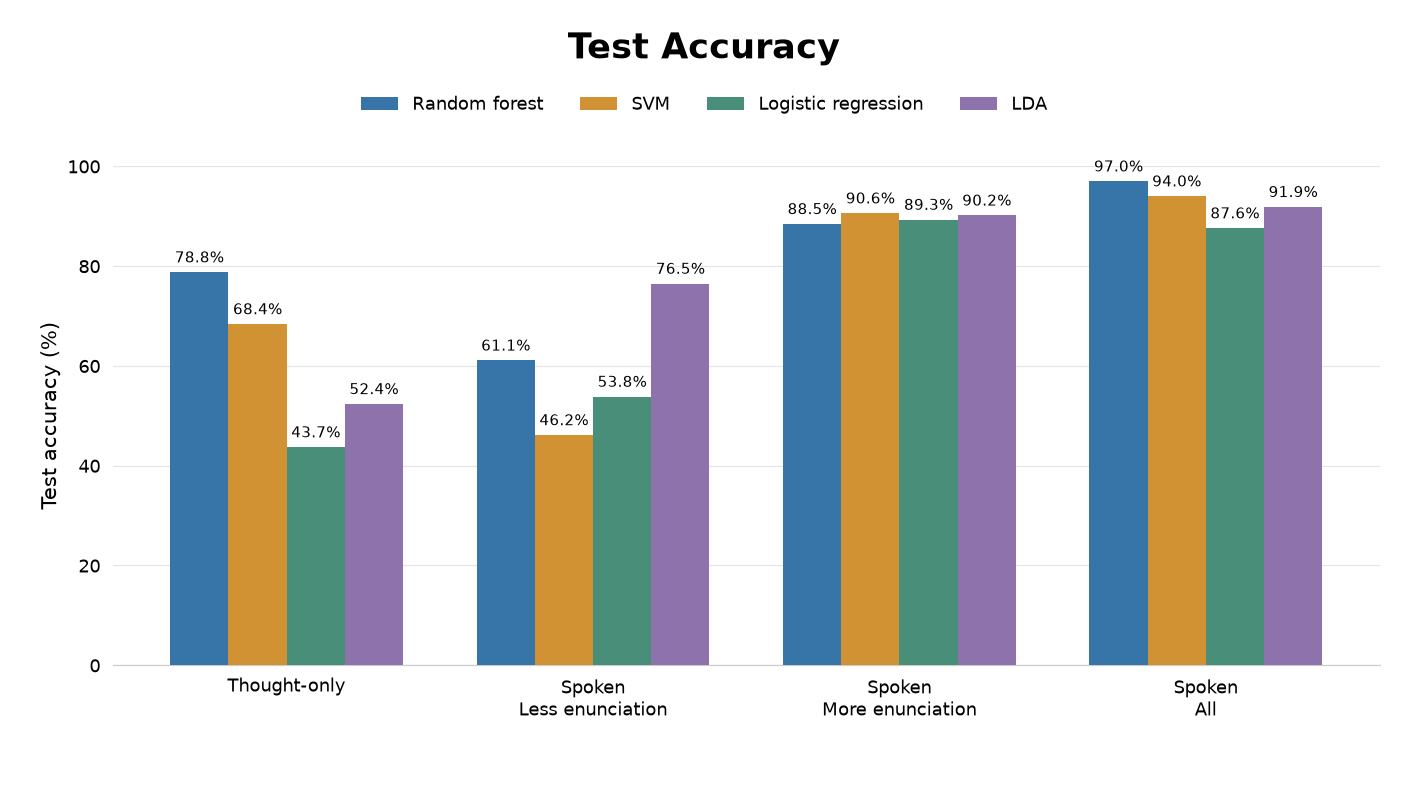

In [18]:
colors = ['#3775A8', '#D09232', '#488E79', '#8E72AC']
fig, ax = plt.subplots(figsize=(12.8, 7.2), facecolor='white')
locations, width = np.arange(len(conditions)), 0.19
for index, (name, color) in enumerate(zip(models, colors)):
    bars = ax.bar(locations + (index - 1.5) * width, 100 * accuracy[name], width,
                  color=color, label=name, zorder=3)
    ax.bar_label(bars, fmt='%.1f%%', padding=4, fontsize=10)
ax.set_ylim(0, 100)
ax.set_yticks(np.arange(0, 101, 20))
ax.set_ylabel('Test accuracy (%)', fontsize=14)
ax.set_xticks(locations, ['Thought-only', 'Spoken\nLess enunciation', 'Spoken\nMore enunciation', 'Spoken\nAll'])
ax.tick_params(axis='both', labelsize=12, length=0, pad=8)
ax.grid(axis='y', color='#E5E5E5', linewidth=0.8, zorder=0)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color('#CCCCCC')
fig.suptitle('Test Accuracy', fontsize=23, y=0.96, fontweight='bold')
fig.legend(*ax.get_legend_handles_labels(), loc='upper center', bbox_to_anchor=(0.5, 0.9), ncol=4, frameon=False, fontsize=12)
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.16, top=0.79)
fig.savefig(OUTPUT / 'test_accuracy.png', dpi=300)
fig.savefig(OUTPUT / 'test_accuracy.svg')
plt.show()

In [19]:
model_files = {}
for (condition, name), model in fitted.items():
    slug = conditions[condition][3] + '_' + name.lower().replace(' ', '_')
    path = OUTPUT / f'{slug}.pkl'
    train, test = splits[condition]
    artifact = {'pipeline': model, 'condition': condition, 'model': name,
                'channels': channels, 'input_shape': [21, 500], 'input_units': 'microvolts',
                'preprocessing': settings, 'feature_bands_hz': BANDS, 'labels': {0: 'not activate', 1: 'activate'},
                'train_recordings': window_info.loc[train, 'recording'].unique().tolist(),
                'test_recordings': window_info.loc[test, 'recording'].unique().tolist()}
    with path.open('wb') as file:
        cloudpickle.dump(artifact, file)
    with path.open('rb') as file:
        reloaded = cloudpickle.load(file)['pipeline']
    expected = predictions.loc[predictions['condition'].eq(condition) & predictions['model'].eq(name), 'predicted']
    np.testing.assert_array_equal(reloaded.predict(X[test]), expected)
    model_files[slug] = str(path.relative_to(ROOT))
print('All 16 exported models reproduce their saved test predictions.')

All 16 exported models reproduce their saved test predictions.


In [20]:
metrics.to_csv(OUTPUT / 'metrics.csv', index=False)
accuracy.to_csv(OUTPUT / 'test_accuracy.csv')
predictions.to_csv(OUTPUT / 'test_predictions.csv', index=False)
class_counts.to_csv(OUTPUT / 'class_counts.csv', index=False)
split_manifest.to_csv(OUTPUT / 'split_manifest.csv', index=False)
quality.to_csv(OUTPUT / 'preprocessing_qc.csv', index=False)
pd.concat(channel_tables, ignore_index=True).to_csv(OUTPUT / 'channel_checks.csv', index=False)
mental_rows = window_info[window_info['experiment'].eq(1)]
mental_rows.to_csv(OUTPUT / 'mental_epoch_metadata.csv', index=False)
np.savez_compressed(OUTPUT / 'mental_epochs.npz', X=X_mental, y=mental_rows['label'].to_numpy(),
                    trial=mental_rows['trial'].to_numpy(), channels=np.array(channels), sfreq=SAMPLE_RATE)

In [21]:
source_paths = {SOURCE / name for name in ['epochs.npz', 'epoch_split.csv', 'metrics.json', 'test_predictions.csv']}
all_sources = sources + [dict(source, experiment=2) for source in reference['sources']]
for source in all_sources:
    source_paths.update(ROOT / source[key] for key in ['eeg_file', 'stimulus_file', 'segment_file'] if source.get(key))
metadata = {
    'target': 'activate vs not activate (blank or other word)', 'test_status': 'Exploratory; spoken Trial 5 was previously inspected',
    'preprocessing': settings, 'channels': channels, 'input_units': 'microvolts', 'input_shape': [21, 500],
    'feature_bands_hz': BANDS, 'features_per_channel': 5, 'feature_count': 105,
    'sources': all_sources, 'mental_quality_checks': quality_rows, 'model_files': model_files,
    'source_sha256': {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest() for path in sorted(source_paths)},
    'model_settings': {name: model[-1].get_params() for name, model in models.items()},
    'splits': {name: {'experiment': exp, 'train_trials': train, 'test_trial': test} for name, (exp, train, test, _) in conditions.items()},
    'software': {name: version(name) for name in ['mne', 'antio', 'numpy', 'scipy', 'scikit-learn', 'cloudpickle']},
    'checks': {'finite_inputs': True, 'disjoint_recordings': True, 'same_spoken_test_epochs': 234,
               'saved_rf_reproduced': True, 'exported_models_verified': 16},
    'notes': ['Fixed model settings; no validation search or test-based tuning.',
              'Mental preprocessing follows the saved spoken pipeline independently per full retained recording.',
              'The +15.6-second correction remains approximate.',
              'Thought-only uses a separate test recording; training sizes and recording protocols differ.',
              'This comparison does not isolate a causal effect of enunciation.'],
}
(OUTPUT / 'metadata.json').write_text(json.dumps(metadata, indent=2, allow_nan=False) + '\n')
print(f'Saved plot, models, predictions, and metadata to {OUTPUT}')

Saved plot, models, predictions, and metadata to /Users/ajayvikram/Desktop/ML/neurotech/results/condition_comparison
